# FYP Experiment: Classifier Comparison on CWRU Bearing Dataset

**Name:** Arleen April Chong
**Matric No:** 22006582
**Purpose:** Empirical comparison of classifiers (RF vs kNN vs SVM vs Naive Bayes vs Decision Tree)
on the CWRU bearing dataset, as requested by examiner feedback, to justify the choice of
Random Forest in the FYP's two-layer Isolation Forest + Random Forest pipeline.

**Data:** CWRU Bearing Data Center, 1797 RPM (0 HP load), 12kHz Drive-End (DE) accelerometer channel.
**Target:** Fault type + severity (12 classes: Normal, Inner Race / Outer Race / Ball faults each
at 0.007", 0.014", 0.021" — plus 0.028" for Inner Race and Ball only, since Outer Race faults were
not tested at that diameter in the original CWRU experiments).


## Important note on the feature set

Your own hardware (ESP32 + MPU-6050) will eventually give you **3-axis** vibration data (X/Y/Z from
one sensor position), so your final 15-feature set (5 statistics × 3 axes) makes sense there.

CWRU's public dataset, however, records from **different physical sensor positions** (Drive-End,
Fan-End, sometimes a Base accelerometer) rather than 3 axes of one sensor. Only the DE channel is
present in *every* recording, so this notebook uses **5 features from the DE channel alone**
(RMS, Peak, Kurtosis, Skewness, Std Dev) to keep the feature vector consistent across all classes.
This is worth stating explicitly in your methodology as a known difference between the CWRU
validation dataset and your own lab-collected data.

## Step 0: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import glob, re

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kurtosis, skew

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

sns.set_style("whitegrid")
%matplotlib inline


## Step 1: Locate and Label the Raw CWRU Files

Point `DATA_DIR` at wherever you've stored the CWRU `.mat` files (or `.npz` if you used a
pre-converted mirror). Each file corresponds to one fault type + severity combination. We parse the
label straight from the filename convention.

**If you're using the original `.mat` files from the official CWRU site**, swap the `np.load(...)`
line in Step 2 for `scipy.io.loadmat(...)` and pull out the `X0XX_DE_time` array instead — the
matlab files use a different key naming convention, so check `.keys()` on one file first.

In [2]:
DATA_DIR = "1797 RPM"  # <-- change this to your actual data folder path

files = sorted(glob.glob(f"{DATA_DIR}/*.npz"))

def format_severity(sev):
    # CWRU severities are 0.007", 0.014", 0.021", 0.028" -- filenames just use "7","14","21","28"
    return f"0.0{sev}" if len(sev) == 2 else f"0.00{sev}"

wanted = []
for f in files:
    name = f.split('/')[-1]
    if name == "1797_Normal.npz":
        wanted.append((f, "Normal"))
    elif re.match(r"1797_IR_\d+_DE12\.npz", name):
        sev = re.search(r"IR_(\d+)_DE12", name).group(1)
        wanted.append((f, f"IR-{format_severity(sev)}"))
    elif re.match(r"1797_B_\d+_DE12\.npz", name):
        sev = re.search(r"B_(\d+)_DE12", name).group(1)
        wanted.append((f, f"B-{format_severity(sev)}"))
    elif re.match(r"1797_OR@6_\d+_DE12\.npz", name):
        sev = re.search(r"OR@6_(\d+)_DE12", name).group(1)
        wanted.append((f, f"OR-{format_severity(sev)}"))

print(f"Found {len(wanted)} files:")
for f, label in wanted:
    print(f"  {label:12s} <- {f.split('/')[-1]}")


Found 12 files:
  B-0.014      <- 1797_B_14_DE12.npz
  B-0.021      <- 1797_B_21_DE12.npz
  B-0.028      <- 1797_B_28_DE12.npz
  B-0.007      <- 1797_B_7_DE12.npz
  IR-0.014     <- 1797_IR_14_DE12.npz
  IR-0.021     <- 1797_IR_21_DE12.npz
  IR-0.028     <- 1797_IR_28_DE12.npz
  IR-0.007     <- 1797_IR_7_DE12.npz
  Normal       <- 1797_Normal.npz
  OR-0.014     <- 1797_OR@6_14_DE12.npz
  OR-0.021     <- 1797_OR@6_21_DE12.npz
  OR-0.007     <- 1797_OR@6_7_DE12.npz


## Step 2: Segment Signals and Extract Features

Each raw file is a single long time-series (~120k-250k samples). We slide a fixed-length window
across the signal (with 50% overlap, to get more training samples out of limited recordings) and
compute the 5 statistical features on each window. This mirrors what you'll eventually do in real
time with the MPU-6050: buffer a window of samples, then compute features on that window before
feeding it to the model.

In [3]:
WINDOW_SIZE = 1024   # samples per window
STEP = 512            # 50% overlap between consecutive windows

def extract_features(window):
    rms = np.sqrt(np.mean(window**2))
    peak = np.max(np.abs(window))
    kurt = kurtosis(window)
    sk = skew(window)
    std = np.std(window)
    return [rms, peak, kurt, sk, std]

rows, labels = [], []

for f, label in wanted:
    data = np.load(f)
    signal = data['DE'].flatten()

    n_windows = (len(signal) - WINDOW_SIZE) // STEP + 1
    for i in range(n_windows):
        window = signal[i*STEP : i*STEP + WINDOW_SIZE]
        rows.append(extract_features(window))
        labels.append(label)

feat_df = pd.DataFrame(rows, columns=["RMS", "Peak", "Kurtosis", "Skewness", "StdDev"])
feat_df["label"] = labels

print("Feature dataframe shape:", feat_df.shape)
feat_df.head()


Feature dataframe shape: (3073, 6)


,RMS,Peak,Kurtosis,Skewness,StdDev,label
0,0.148520,0.644218,1.199027,-0.031916,0.148444,B-0.014
1,0.142460,0.644218,1.160292,-0.018659,0.142371,B-0.014
2,0.111538,0.462290,1.096605,0.041843,0.111411,B-0.014
3,0.098023,0.462290,1.487607,0.059088,0.097908,B-0.014
4,0.094171,0.385946,0.325188,-0.046952,0.094035,B-0.014


In [4]:
# Save the extracted features so you don't have to re-run the windowing step every time
feat_df.to_csv("cwru_features.csv", index=False)


## Step 3: Check Class Balance

/tmp/ipykernel_573/1495191043.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='label', data=feat_df, order=order, palette="viridis")


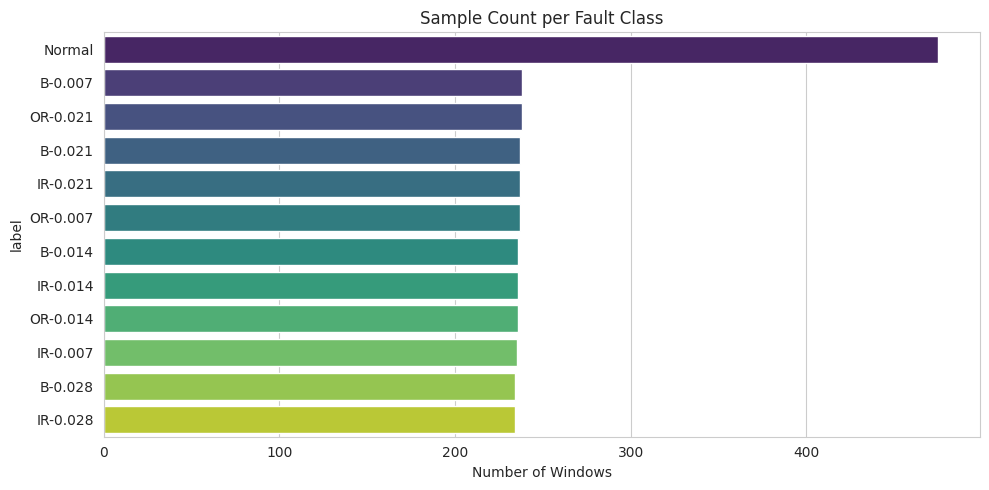

label
Normal      475
B-0.007     238
OR-0.021    238
B-0.021     237
IR-0.021    237
OR-0.007    237
B-0.014     236
IR-0.014    236
OR-0.014    236
IR-0.007    235
B-0.028     234
IR-0.028    234
Name: count, dtype: int64

In [5]:
plt.figure(figsize=(10, 5))
order = feat_df['label'].value_counts().index
sns.countplot(y='label', data=feat_df, order=order, palette="viridis")
plt.title("Sample Count per Fault Class")
plt.xlabel("Number of Windows")
plt.tight_layout()
plt.savefig("cwru_class_distribution.png", dpi=150)
plt.show()

feat_df['label'].value_counts()


**Note for your report:** classes are fairly balanced here because windowing with overlap
produces a similar number of samples per file — but the *raw recording lengths* differ slightly
per class (visible in the small differences in window counts), which is worth mentioning if any
class has noticeably fewer samples.

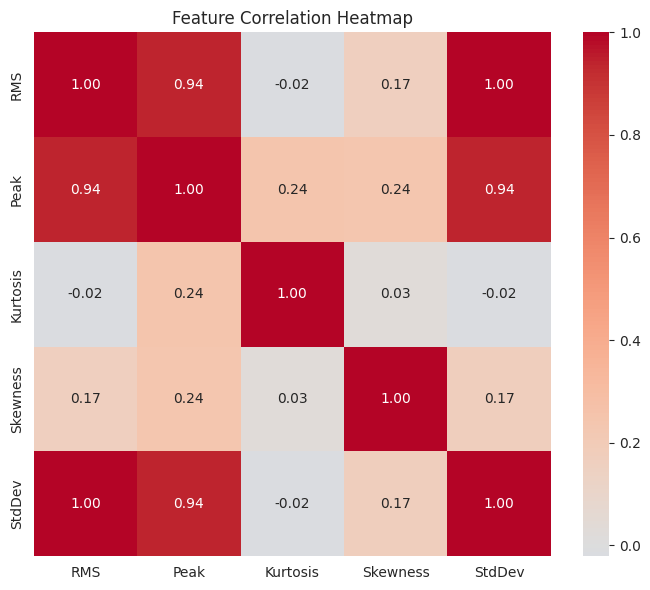

In [6]:
plt.figure(figsize=(7, 6))
sns.heatmap(feat_df[["RMS", "Peak", "Kurtosis", "Skewness", "StdDev"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("cwru_feature_correlation.png", dpi=150)
plt.show()


**Note for your report:** RMS and StdDev are almost always highly correlated for vibration
signals (both measure signal energy/spread around similar reference points) — worth commenting on
whether this redundancy matters for tree-based models (generally fine) vs. Logistic Regression
(can inflate coefficient instability, though prediction accuracy is usually still okay).

## Step 4: Preprocessing

We encode the text labels into integers with `LabelEncoder` (needed for some sklearn internals),
split into train/test sets (80/20, stratified so every class is represented proportionally in both
sets), and scale features with `StandardScaler`.

In [7]:
le = LabelEncoder()
X = feat_df[["RMS", "Peak", "Kurtosis", "Skewness", "StdDev"]]
y = le.fit_transform(feat_df["label"])

print("Classes:", list(le.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Classes: ['B-0.007', 'B-0.014', 'B-0.021', 'B-0.028', 'IR-0.007', 'IR-0.014', 'IR-0.021', 'IR-0.028', 'Normal', 'OR-0.007', 'OR-0.014', 'OR-0.021']
Training set size: (2458, 5)
Testing set size: (615, 5)


## Step 5: Initiate the Classifiers

Per your examiner's feedback, we compare Random Forest against kNN, SVM, Naive Bayes, and Decision
Tree — the same empirical comparison structure as BDA Lab 6, but here applied to your own FYP
validation dataset and a genuine multi-class fault diagnosis problem instead of binary
classification.

In [8]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(kernel='rbf', random_state=42)
}

for name, model in models.items():
    print(f"{name}: {model}")


Decision Tree: DecisionTreeClassifier(random_state=42)
K-Nearest Neighbors: KNeighborsClassifier()
Naive Bayes: GaussianNB()
Random Forest: RandomForestClassifier(random_state=42)
Support Vector Machine: SVC(random_state=42)


## Step 6: Train Each Model and Compare Scores

For multi-class problems, Precision/Recall/F1 need an averaging strategy across classes.
We use **macro averaging** (unweighted mean across all 12 classes), which treats every fault class
as equally important regardless of how many samples it has — appropriate here since correctly
catching a rare severe fault matters just as much as a common one.

In [9]:
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    test_acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)

    results.append({
        "Model": name,
        "Test Accuracy": round(test_acc, 4),
        "Macro Precision": round(precision, 4),
        "Macro Recall": round(recall, 4),
        "Macro F1-Score": round(f1, 4),
        "CV Mean Accuracy": round(cv_scores.mean(), 4),
        "CV Std": round(cv_scores.std(), 4)
    })

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False)
results_df


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score,CV Mean Accuracy,CV Std
3,Random Forest,0.9675,0.9645,0.9648,0.9645,0.9548,0.0139
1,K-Nearest Neighbors,0.9382,0.9360,0.9331,0.9315,0.9312,0.0125
0,Decision Tree,0.9350,0.9295,0.9299,0.9290,0.9471,0.0104
2,Naive Bayes,0.9187,0.9175,0.9118,0.9023,0.9264,0.0086
4,Support Vector Machine,0.8309,0.8090,0.8165,0.7975,0.8295,0.0052


In [10]:
# Full per-class report for your top-performing model (fill in the name once you see results_df)
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

print(f"--- Classification Report: {best_model_name} ---")
print(classification_report(y_test, y_pred_best, target_names=le.classes_, zero_division=0))


--- Classification Report: Random Forest ---
              precision    recall  f1-score   support

     B-0.007       0.98      0.98      0.98        48
     B-0.014       0.85      0.83      0.84        47
     B-0.021       0.89      0.85      0.87        48
     B-0.028       1.00      1.00      1.00        47
    IR-0.007       0.98      1.00      0.99        47
    IR-0.014       0.98      1.00      0.99        47
    IR-0.021       1.00      0.96      0.98        47
    IR-0.028       1.00      1.00      1.00        47
      Normal       1.00      1.00      1.00        95
    OR-0.007       1.00      1.00      1.00        47
    OR-0.014       0.94      0.96      0.95        47
    OR-0.021       0.96      1.00      0.98        48

    accuracy                           0.97       615
   macro avg       0.96      0.96      0.96       615
weighted avg       0.97      0.97      0.97       615



## Step 7: Visualizations

/tmp/ipykernel_573/1125467803.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Test Accuracy", y="Model", data=results_df, palette="mako")


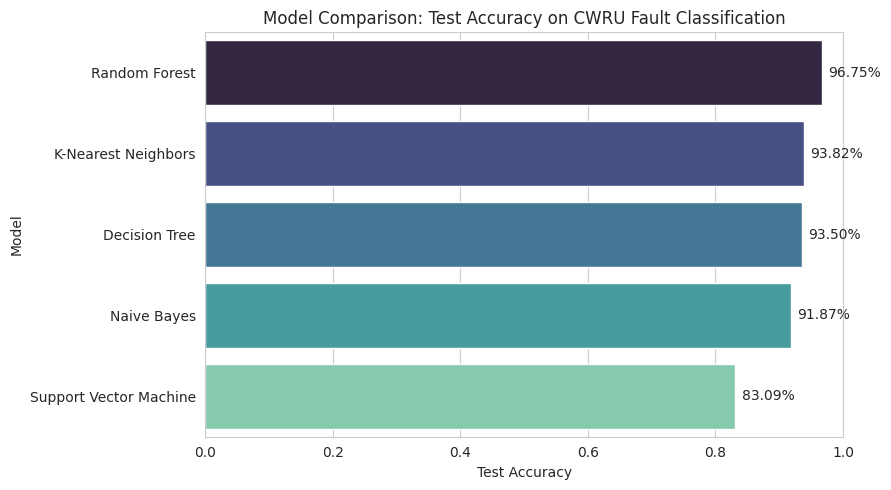

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(x="Test Accuracy", y="Model", data=results_df, palette="mako")
plt.xlim(0, 1)
plt.title("Model Comparison: Test Accuracy on CWRU Fault Classification")
for i, v in enumerate(results_df["Test Accuracy"]):
    plt.text(v + 0.01, i, f"{v:.2%}", va='center')
plt.tight_layout()
plt.savefig("cwru_model_accuracy_comparison.png", dpi=150)
plt.show()


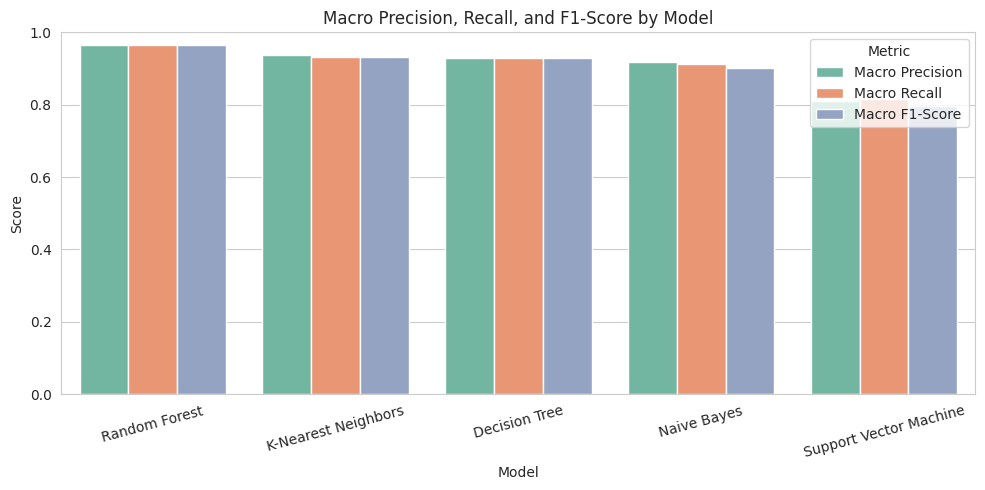

In [12]:
metrics_melted = results_df.melt(
    id_vars="Model",
    value_vars=["Macro Precision", "Macro Recall", "Macro F1-Score"],
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(x="Model", y="Score", hue="Metric", data=metrics_melted, palette="Set2")
plt.title("Macro Precision, Recall, and F1-Score by Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("cwru_precision_recall_f1.png", dpi=150)
plt.show()


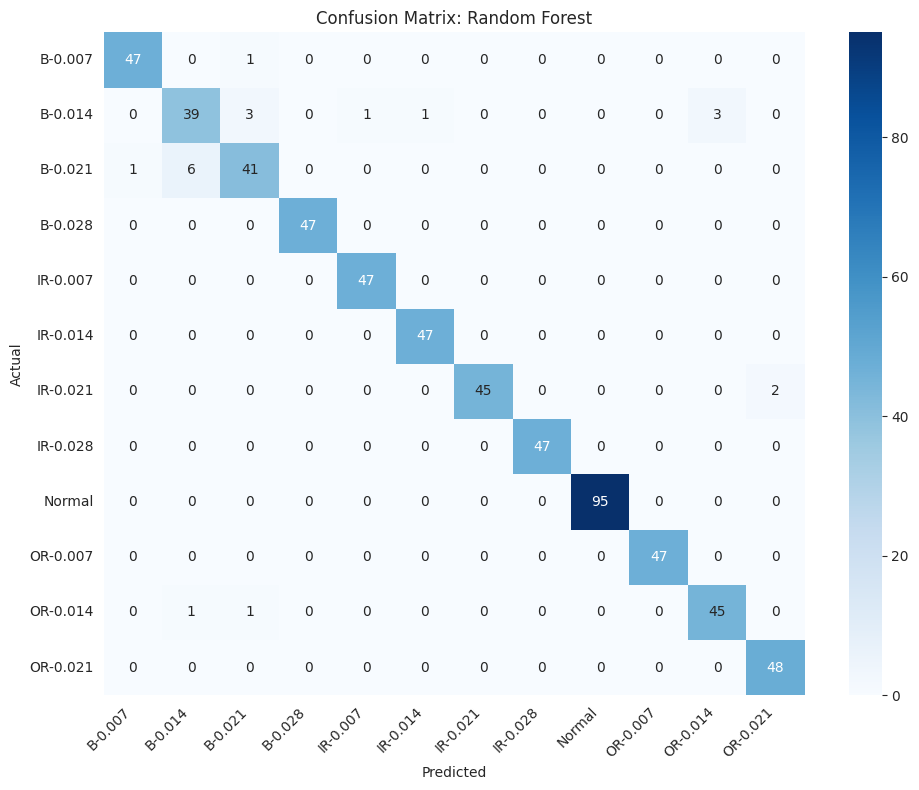

In [13]:
# Confusion matrix for the best-performing model -- shows exactly which fault types get confused
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix: {best_model_name}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("cwru_confusion_matrix.png", dpi=150)
plt.show()


**Note for your report:** in the confusion matrix, pay close attention to *which* classes get
confused with each other. Misclassifying between two severities of the *same* fault type
(e.g. IR-0.007 predicted as IR-0.014) is a much less serious error than misclassifying between two
different fault *locations* (e.g. an Inner Race fault predicted as Outer Race), since the latter
could lead to inspecting or replacing the wrong part.

## Step 8: Feature Importance (Random Forest)

/tmp/ipykernel_573/4291673383.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="mako")


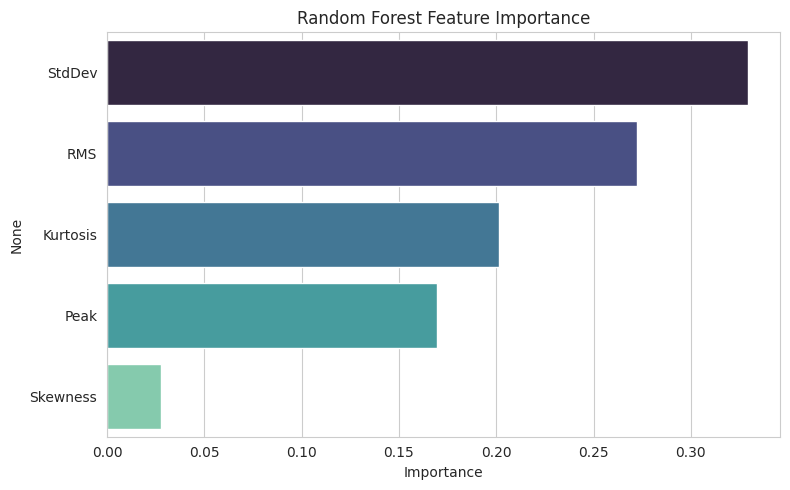

StdDev      0.329298
RMS         0.272461
Kurtosis    0.201247
Peak        0.169503
Skewness    0.027491
dtype: float64

In [14]:
rf_model = models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette="mako")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("cwru_feature_importance.png", dpi=150)
plt.show()

importances


## Discussion Points for Your FYP Report

**Points to build your justification from (write this in your own words):**

- State which model won on Test Accuracy and which won on CV Mean Accuracy — same nuance as
  Lab 6: a model that wins on one split but not consistently across folds is a weaker
  justification than one that wins on both.
- Since this is multi-class (12 classes) rather than binary, macro-averaged Precision/Recall/F1
  matter more than accuracy alone — a model could get high accuracy just by doing well on the
  common classes (like Normal) while doing poorly on rarer severity classes. Point to the
  per-class `classification_report` output to check if any specific fault class has a much lower
  F1-score than the others.
- Use the confusion matrix to discuss *where* errors happen — adjacent severities of the same
  fault type being confused is a much more forgivable error than confusing fault locations
  entirely (see note above).
- Tie this back to your two-layer pipeline: this experiment justifies *why* Random Forest was
  chosen as the classification layer (after Isolation Forest handles anomaly detection) — if
  Random Forest wins here too, it directly supports your existing architecture decision with
  empirical evidence, exactly as your examiner requested.
- Be explicit that this classifier comparison used the CWRU dataset for validation, and that your
  own lab-collected data (3-axis, real ESP32 + MPU-6050 hardware) will be used to retrain and
  re-validate the same comparison in FYP 2, per your existing methodology.

**Link sources to cite:**
- CWRU Bearing Data Center (official dataset source): https://engineering.case.edu/bearingdatacenter
- Scikit-learn Random Forest documentation: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- Scikit-learn multi-class and averaging strategies: https://scikit-learn.org/stable/modules/model_evaluation.html#multiclass-and-multilabel-classification
- Scikit-learn Naive Bayes documentation: https://scikit-learn.org/stable/modules/naive_bayes.html